## Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

final_dt = pd.read_csv('final_dataset.csv')

In [2]:
final_dt.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2448 entries, 0 to 2447
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   StateFIPS                2448 non-null   int64  
 1   State_x                  2448 non-null   object 
 2   Year                     2448 non-null   int64  
 3   Exposure_Value           2448 non-null   float64
 4   Pollutant                2448 non-null   object 
 5   State_y                  2448 non-null   object 
 6   State Code               2448 non-null   int64  
 7   Deaths                   2448 non-null   int64  
 8   Population               2448 non-null   float64
 9   Crude Rate               2448 non-null   float64
 10  Child_Asthma_Prevalence  1112 non-null   float64
dtypes: float64(4), int64(4), object(3)
memory usage: 210.5+ KB


In [3]:
final_dt.head()

,StateFIPS,State_x,Year,Exposure_Value,Pollutant,State_y,State Code,Deaths,Population,Crude Rate,Child_Asthma_Prevalence
0,1,Alabama,2005,0.83,Benzene,Alabama,1,47090,4569805.0,1030.5,NaN
1,1,Alabama,2005,2.56,Formaldehyde,Alabama,1,47090,4569805.0,1030.5,NaN
2,1,Alabama,2005,2.71,Acetaldehyde,Alabama,1,47090,4569805.0,1030.5,NaN
3,1,Alabama,2005,0.61,Carbon tetrachloride,Alabama,1,47090,4569805.0,1030.5,NaN
4,1,Alabama,2005,0.04,"1,3-butadiene",Alabama,1,47090,4569805.0,1030.5,NaN


### Mortality Focused Correlation

In [4]:
## Mortality-focused dataset
final_mortality = final_dt.copy()

# Asthma-focused dataset
final_asthma = final_dt.dropna(subset=['Child_Asthma_Prevalence']).copy()

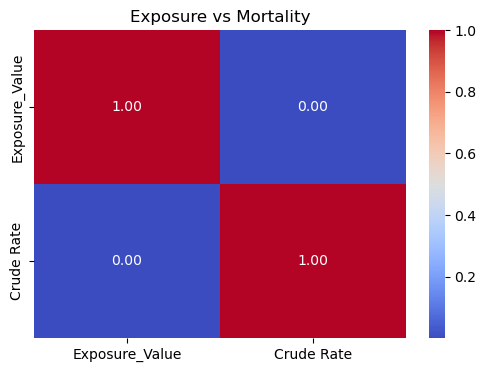

In [5]:
corr_mortality = final_mortality[
    [
        'Exposure_Value', 
        'Crude Rate'
    ]
].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(corr_mortality, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Exposure vs Mortality')
plt.show()

In [6]:
corr_asthma = final_asthma[['Exposure_Value', 'Child_Asthma_Prevalence']].corr()

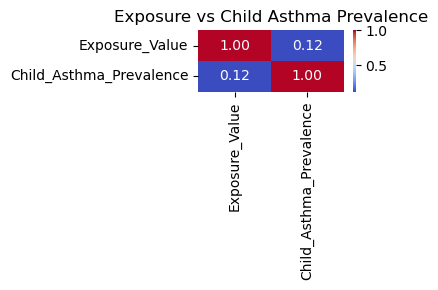

In [7]:
plt.figure(figsize=(4,3))
sns.heatmap(corr_asthma, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Exposure vs Child Asthma Prevalence')
plt.tight_layout()
plt.show()

### Pollutant‑Specific Correlation with Mortality (Crude Rate)

In [8]:
pollutant_corr_mort = (
    final_dt.groupby('Pollutant')[['Exposure_Value', 'Crude Rate']]
         .corr()
         .unstack()
         .iloc[:, 1]   # correlation between Exposure_Value and Crude Rate
)

pollutant_corr_mort

Pollutant
1,3-butadiene               -0.185822
Acetaldehyde                 0.073272
Benzene                     -0.143554
Carbon tetrachloride        -0.054768
Diesel Particulate Matter   -0.158308
Ethylene oxide              -0.034741
Formaldehyde                 0.130978
Napthalene                  -0.160256
Name: (Exposure_Value, Crude Rate), dtype: float64

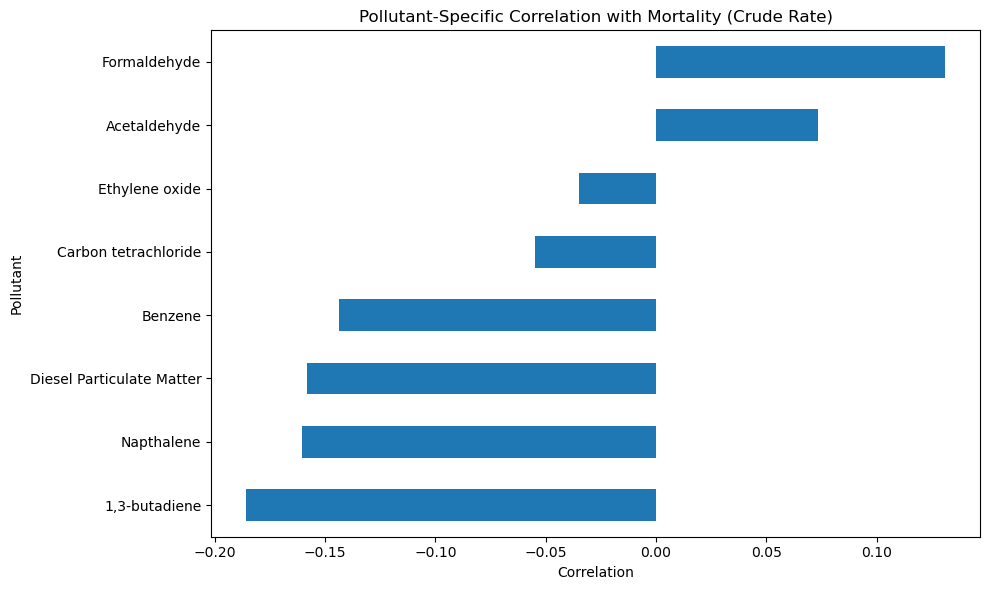

In [9]:
## Visualizing pollutant‑specific correlations
plt.figure(figsize=(10,6))
pollutant_corr_mort.sort_values().plot(kind='barh')
plt.title('Pollutant-Specific Correlation with Mortality (Crude Rate)')
plt.xlabel('Correlation')
plt.tight_layout()
plt.show()

### Pollutant‑Specific Correlation with Asthma

In [10]:
pollutant_corr_asthma = (
    final_asthma.groupby('Pollutant')[['Exposure_Value', 'Child_Asthma_Prevalence']]
                .corr()
                .unstack()
                .iloc[:, 1]
)

pollutant_corr_asthma

Pollutant
1,3-butadiene                0.374339
Acetaldehyde                 0.284836
Benzene                      0.373072
Carbon tetrachloride         0.365924
Diesel Particulate Matter    0.323495
Ethylene oxide               0.103948
Formaldehyde                 0.338063
Napthalene                   0.358418
Name: (Exposure_Value, Child_Asthma_Prevalence), dtype: float64

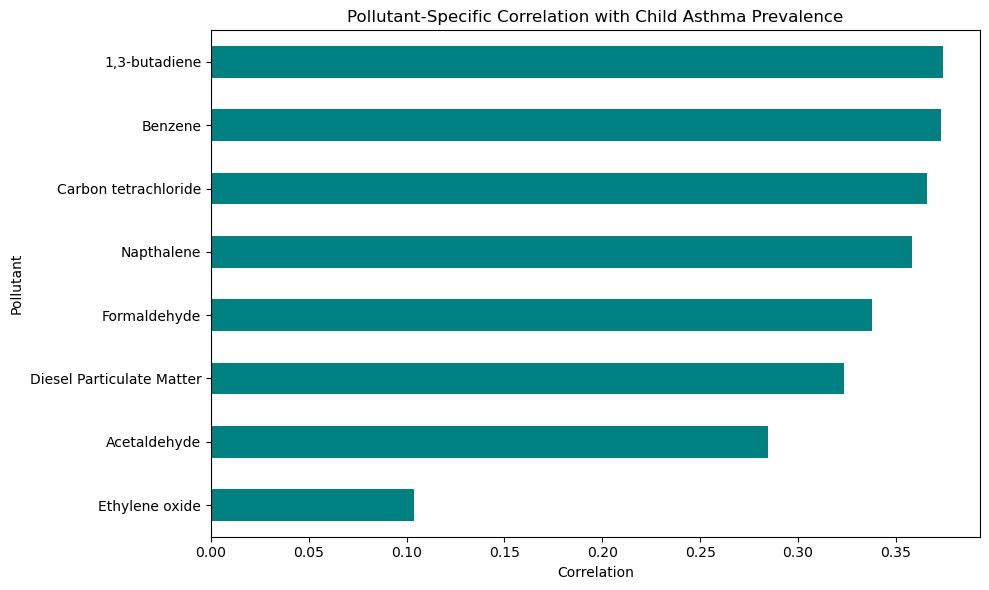

In [11]:
## Visualizing pollutant‑specific correlations (For Asthma)
plt.figure(figsize=(10,6))
pollutant_corr_asthma.sort_values().plot(kind='barh', color='teal')
plt.title('Pollutant-Specific Correlation with Child Asthma Prevalence')
plt.xlabel('Correlation')
plt.tight_layout()
plt.show()

In [13]:
final_asthma = final_asthma.dropna(subset=['Child_Asthma_Prevalence'])

print(
    final_asthma[
        ['Exposure_Value', 'Child_Asthma_Prevalence']
    ].describe().round(2)
)

       Exposure_Value  Child_Asthma_Prevalence
count         1112.00                  1112.00
mean             0.36                     8.38
std              0.43                     2.06
min              0.00                     4.30
25%              0.01                     6.90
50%              0.20                     8.00
75%              0.54                     9.60
max              2.32                    16.00


In [14]:
print(
    final_asthma[
        ['Exposure_Value', 'Child_Asthma_Prevalence']
    ].isnull().sum()
)

Exposure_Value             0
Child_Asthma_Prevalence    0
dtype: int64


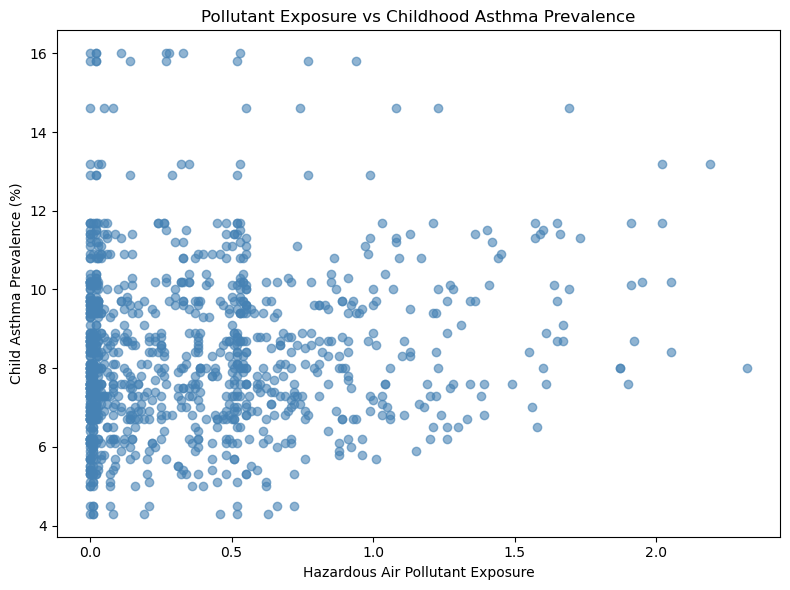

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    final_asthma['Exposure_Value'],
    final_asthma['Child_Asthma_Prevalence'],
    alpha=0.6,
    color='steelblue'
)

plt.xlabel('Hazardous Air Pollutant Exposure')
plt.ylabel('Child Asthma Prevalence (%)')

plt.title(
    'Pollutant Exposure vs Childhood Asthma Prevalence'
)

plt.tight_layout()
plt.show()

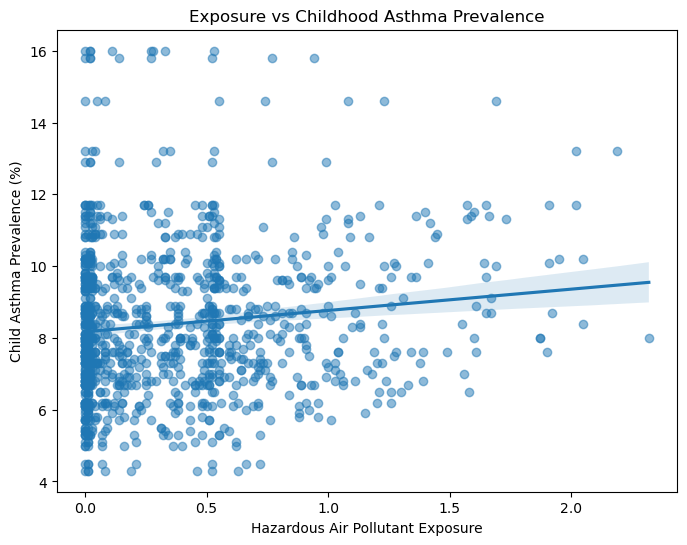

In [16]:
import seaborn as sns

plt.figure(figsize=(8,6))

sns.regplot(
    data=final_asthma,
    x='Exposure_Value',
    y='Child_Asthma_Prevalence',
    scatter_kws={'alpha':0.5}
)

plt.xlabel('Hazardous Air Pollutant Exposure')
plt.ylabel('Child Asthma Prevalence (%)')
plt.title('Exposure vs Childhood Asthma Prevalence')

plt.show()